# Mercatto — Análise exploratória e técnicas analíticas

**Objetivo:** responder às perguntas gerenciais definidas em `docs/01_planejamento.md` usando a base tratada
(`data/processed/bi.db`). Este notebook cobre a **Etapa 3** da prova:

1. Visão geral e estatística descritiva
2. KPIs e comparações por dimensão (tempo, canal, região, categoria)
3. Margem × desconto (Black Friday) e devoluções
4. **Técnica analítica 1 — Segmentação de clientes (RFM + K-means)**
5. **Técnica analítica 2 — Previsão de receita (Holt-Winters, validação com origem móvel)**
6. **Técnica analítica 3 — Detecção de anomalias na receita diária**
7. Avaliação crítica e limitações

> Pré-requisito: rodar `python run_all.py` na raiz do projeto (gera a base, faz o ETL e a validação).

In [1]:
import sys, sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src import analise

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
reais = mtick.FuncFormatter(lambda v, _: f"R$ {v/1e6:,.1f} mi" if abs(v) >= 1e6 else f"R$ {v/1e3:,.0f} mil")

con = analise.conectar(RAIZ / "data" / "processed" / "bi.db")
pedidos = analise.carregar_pedidos(con)
vendas = analise.carregar_vendas(con)
ent = pedidos[pedidos["status"] == "Entregue"]
vend_ent = vendas[vendas["status"] == "Entregue"]
print(f"{len(pedidos):,} pedidos | {len(vendas):,} itens | {pedidos['id_cliente'].nunique():,} clientes com pedido")

59,437 pedidos | 105,890 itens | 6,951 clientes com pedido


## 1. Visão geral da base tratada

In [2]:
tabelas = ["dim_calendario", "dim_cliente", "dim_produto", "dim_loja", "fato_pedido", "fato_item_pedido"]
pd.DataFrame({t: [con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]] for t in tabelas}, index=["linhas"]).T

,linhas
dim_calendario,1096
dim_cliente,8000
dim_produto,120
dim_loja,11
fato_pedido,59437
fato_item_pedido,105890


In [3]:
pedidos[["status", "canal", "forma_pagamento", "regiao_cliente"]].describe()

,status,canal,forma_pagamento,regiao_cliente
count,59437,59437,59437,59437
unique,3,2,5,5
top,Entregue,Loja física,Cartão de Crédito,Sudeste
freq,53173,29965,31087,25828


In [4]:
pedidos["status"].value_counts(normalize=True).rename("participação").to_frame()

,participação
status,
Entregue,0.89
Devolvido,0.07
Cancelado,0.04


## 2. Estatística descritiva

Valor dos pedidos entregues (receita líquida por pedido). A média bem acima da mediana e a assimetria positiva
mostram uma distribuição concentrada em pedidos baratos, com uma cauda longa de pedidos caros
(eletrônicos e informática).

In [5]:
desc = ent["receita_liquida"].describe(percentiles=[.25, .5, .75, .9, .99])
desc["assimetria"] = ent["receita_liquida"].skew()
desc["coef_variacao"] = ent["receita_liquida"].std() / ent["receita_liquida"].mean()
desc.to_frame("valor do pedido (R$)")

,valor do pedido (R$)
count,"53,173.00"
mean,900.18
std,"1,162.92"
min,31.43
25%,215.01
50%,462.21
75%,"1,087.52"
90%,"2,192.95"
99%,"5,911.93"
max,"17,310.01"


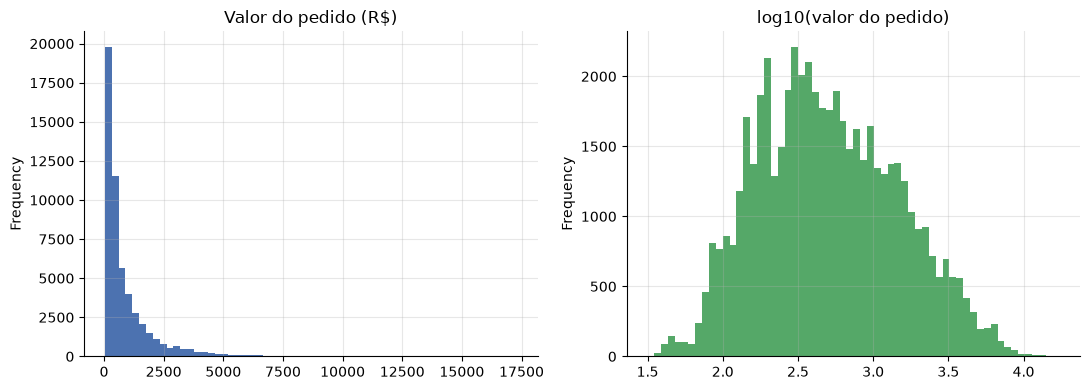

In [6]:
fig, ax = plt.subplots(1, 2)
ent["receita_liquida"].plot.hist(bins=60, ax=ax[0], color="#4C72B0", title="Valor do pedido (R$)")
np.log10(ent["receita_liquida"]).plot.hist(bins=60, ax=ax[1], color="#55A868", title="log10(valor do pedido)")
plt.tight_layout()

In [7]:
num = ent[["qtd_itens", "receita_bruta", "valor_desconto", "receita_liquida", "margem_bruta", "valor_frete"]]
num.corr().round(2)

,qtd_itens,receita_bruta,valor_desconto,receita_liquida,margem_bruta,valor_frete
qtd_itens,1.00,0.42,0.24,0.42,0.46,-0.23
receita_bruta,0.42,1.00,0.59,1.00,0.78,-0.26
valor_desconto,0.24,0.59,1.00,0.51,0.10,-0.14
receita_liquida,0.42,1.00,0.51,1.00,0.82,-0.26
margem_bruta,0.46,0.78,0.10,0.82,1.00,-0.25
valor_frete,-0.23,-0.26,-0.14,-0.26,-0.25,1.00


## 3. KPIs por ano (fórmulas em `docs/01_planejamento.md`)

In [8]:
anual = analise.kpis_por_ano(pedidos)
fmt = anual.copy()
for c in [c for c in fmt.columns if c.endswith("_pct")]:
    fmt[c] = (fmt[c] * 100).round(1).astype(str) + "%"
fmt.T

ano,2023,2024,2025
receita_liquida,"10,206,772.20","15,479,122.18","22,179,119.32"
margem_bruta,"2,407,344.75","3,629,835.39","5,216,062.99"
margem_bruta_pct,23.6%,23.4%,23.5%
pedidos_entregues,11551,17147,24475
ticket_medio,883.63,902.73,906.19
desconto_medio_pct,6.1%,6.1%,6.0%
taxa_devolucao_pct,7.1%,7.1%,7.5%
taxa_cancelamento_pct,2.8%,3.6%,3.8%
participacao_online_pct,37.5%,47.6%,54.6%
clientes_ativos,3039,4301,5665


## 4. Tendência e sazonalidade

canal,Loja física,Online
data_pedido,,
2023-01-01,0.64,0.36
2024-01-01,0.54,0.47
2025-01-01,0.47,0.54


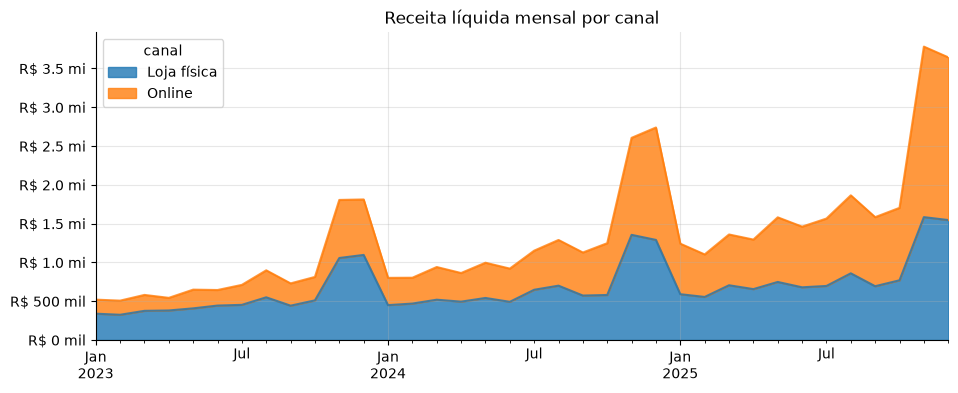

In [9]:
mensal = ent.groupby([pd.Grouper(key="data_pedido", freq="MS"), "canal"])["receita_liquida"].sum().unstack()
ax = mensal.plot.area(stacked=True, alpha=.8, title="Receita líquida mensal por canal")
ax.yaxis.set_major_formatter(reais); ax.set_xlabel("")
mensal.div(mensal.sum(axis=1), axis=0).resample("YS").mean().round(3)

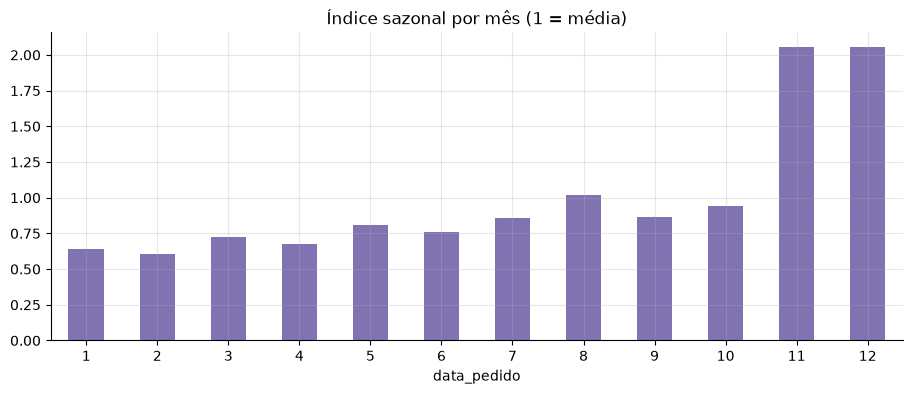

In [10]:
saz = ent.groupby(ent["data_pedido"].dt.month)["receita_liquida"].sum()
(saz / saz.mean()).plot.bar(title="Índice sazonal por mês (1 = média)", color="#8172B2", rot=0);

## 5. Comparações por dimensão

In [11]:
cat = vend_ent.groupby("categoria").agg(receita=("receita_liquida", "sum"), margem=("margem_bruta", "sum"),
                                        itens=("quantidade", "sum"), desconto=("valor_desconto", "sum"),
                                        bruta=("receita_bruta", "sum"))
cat["margem_%"] = cat["margem"] / cat["receita"] * 100
cat["desconto_%"] = cat["desconto"] / cat["bruta"] * 100
cat["part_receita_%"] = cat["receita"] / cat["receita"].sum() * 100
cat.sort_values("receita", ascending=False)[["receita", "part_receita_%", "margem_%", "desconto_%", "itens"]]

,receita,part_receita_%,margem_%,desconto_%,itens
categoria,,,,,
Eletrônicos,"21,597,912.11",45.12,12.60,6.37,26583
Casa e Cozinha,"7,976,725.21",16.67,32.03,5.68,18351
Informática,"7,629,277.45",15.94,16.87,6.18,16067
Esporte e Lazer,"4,704,470.08",9.83,35.41,5.58,12736
Moda,"3,372,123.72",7.05,53.42,5.59,18071
Beleza e Saúde,"2,584,505.13",5.40,47.32,5.44,15516


In [12]:
reg = ent.pivot_table(index="regiao_cliente", columns="ano", values="receita_liquida", aggfunc="sum")
reg["cresc_23_25_%"] = (reg[2025] / reg[2023] - 1) * 100
reg["part_2025_%"] = reg[2025] / reg[2025].sum() * 100
reg.sort_values("cresc_23_25_%", ascending=False)

ano,2023,2024,2025,cresc_23_25_%,part_2025_%
regiao_cliente,,,,,
Nordeste,"2,068,908.12","3,466,878.11","5,368,499.73",159.48,24.21
Centro-Oeste,"765,067.05","1,214,864.15","1,761,991.36",130.31,7.94
Sul,"1,581,891.47","2,442,965.94","3,523,900.36",122.76,15.89
Norte,"1,078,666.60","1,553,294.45","2,279,960.38",111.37,10.28
Sudeste,"4,712,238.96","6,801,119.53","9,244,767.49",96.19,41.68


In [13]:
lojas = vendas[(vendas["status"] == "Entregue") & (vendas["canal"] == "Loja física")]
lojas.pivot_table(index="nome_loja", columns="ano", values="receita_liquida", aggfunc="sum").fillna(0).round(0)

ano,2023,2024,2025
nome_loja,,,
Mercatto Barra,"656,138.00","780,932.00","983,297.00"
Mercatto Belém,"684,933.00","784,641.00","1,025,917.00"
Mercatto Brasília,"488,116.00","625,257.00","810,934.00"
Mercatto Campinas,"763,146.00","979,556.00","1,261,416.00"
Mercatto Curitiba,"515,632.00","635,682.00","799,610.00"
Mercatto Paulista,"803,879.00","1,001,742.00","1,174,074.00"
Mercatto Porto Alegre,"483,264.00","681,198.00","787,315.00"
Mercatto Recife,0.00,"781,104.00","1,212,951.00"
Mercatto Salvador,"1,288,185.00","1,018,061.00","1,143,450.00"


## 6. Margem × desconto e o efeito da Black Friday

Pergunta gerencial: *a Black Friday é lucrativa?* Comparamos a margem por faixa de desconto e por categoria
dentro e fora da janela da Black Friday (sexta a Cyber Monday).

In [14]:
vend_ent = vend_ent.assign(faixa_desconto=pd.cut(vend_ent["desconto_pct"], [-.01, 0, .10, .20, .30, .5],
                                                 labels=["0%", "1-10%", "11-20%", "21-30%", ">30%"]))
t = vend_ent.groupby(["categoria", "faixa_desconto"], observed=True).apply(
    lambda g: g["margem_bruta"].sum() / g["receita_liquida"].sum() * 100).unstack().round(1)
t

faixa_desconto,0%,1-10%,11-20%,21-30%,>30%
categoria,,,,,
Beleza e Saúde,50.20,46.60,40.00,31.40,24.40
Casa e Cozinha,35.90,31.10,23.10,12.70,2.20
Eletrônicos,18.20,12.00,1.50,-12.10,-27.90
Esporte e Lazer,39.10,34.40,26.90,15.90,8.10
Informática,22.10,16.10,6.50,-6.80,-23.10
Moda,55.90,52.80,47.50,39.90,32.30


periodo,Black Friday,Resto do ano
categoria,,
Beleza e Saúde,37.10,47.70
Casa e Cozinha,18.20,32.60
Eletrônicos,-8.60,13.70
Esporte e Lazer,22.50,36.00
Informática,-3.30,17.90
Moda,44.20,53.80


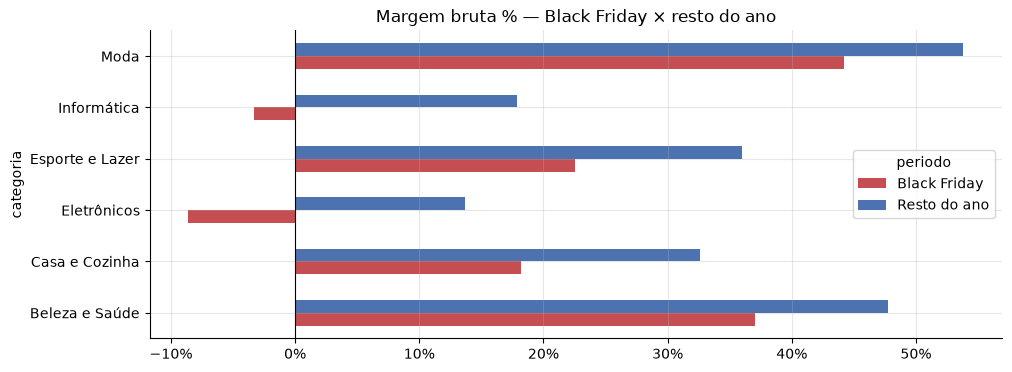

In [15]:
bf = vend_ent.assign(periodo=np.where(vend_ent["evento_comercial"] == "Black Friday", "Black Friday", "Resto do ano"))
m = bf.groupby(["categoria", "periodo"]).apply(lambda g: g["margem_bruta"].sum() / g["receita_liquida"].sum() * 100).unstack()
ax = m.plot.barh(title="Margem bruta % — Black Friday × resto do ano", color=["#C44E52", "#4C72B0"])
ax.axvline(0, color="black", lw=.8); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
m.round(1)

In [16]:
prejuizo = vend_ent[(vend_ent["evento_comercial"] == "Black Friday") & (vend_ent["margem_bruta"] < 0)]
print(f"Itens vendidos com margem negativa na Black Friday: {len(prejuizo):,}")
print(f"Prejuízo bruto nesses itens: R$ {-prejuizo['margem_bruta'].sum():,.2f}")
prejuizo.groupby("categoria")["margem_bruta"].sum().sort_values().round(2)

Itens vendidos com margem negativa na Black Friday: 1,892
Prejuízo bruto nesses itens: R$ 145,614.13


categoria
Eletrônicos       -120,044.34
Informática        -25,419.22
Casa e Cozinha        -123.89
Esporte e Lazer        -26.68
Name: margem_bruta, dtype: float64

## 7. Devoluções

In [17]:
base = vendas[vendas["status"] != "Cancelado"].drop_duplicates(["id_pedido", "categoria"])
dev = base.pivot_table(index="categoria", columns="canal", values="status",
                       aggfunc=lambda s: (s == "Devolvido").mean() * 100)
dev["geral"] = base.groupby("categoria")["status"].apply(lambda s: (s == "Devolvido").mean() * 100)
dev.sort_values("geral", ascending=False).round(1)

canal,Loja física,Online,geral
categoria,,,
Moda,13.10,14.80,13.90
Eletrônicos,5.80,8.20,7.00
Esporte e Lazer,5.60,8.40,7.00
Beleza e Saúde,5.30,8.10,6.70
Informática,5.60,7.60,6.60
Casa e Cozinha,5.30,7.60,6.40


## 8. Técnica 1 — Segmentação de clientes (RFM + K-means)

- **R**ecência: dias desde a última compra entregue até 31/12/2025
- **F**requência: nº de pedidos entregues
- **M**onetário: receita líquida acumulada

As três variáveis são transformadas com `log(1+x)` (reduz a assimetria) e padronizadas (média 0, desvio 1),
para que o valor monetário não domine a distância. O número de grupos *k* é escolhido pelo **método do
cotovelo** e pelo **coeficiente de silhouette**, restrito a 3–6 grupos para manter os segmentos acionáveis.

k escolhido = 4 | silhouette = 0.340


,k,inercia,silhouette
0,2,"10,593.25",0.40
1,3,"8,046.28",0.31
2,4,"6,090.79",0.34
3,5,"5,081.74",0.31
4,6,"4,383.31",0.30
5,7,"3,891.54",0.30
6,8,"3,430.27",0.30


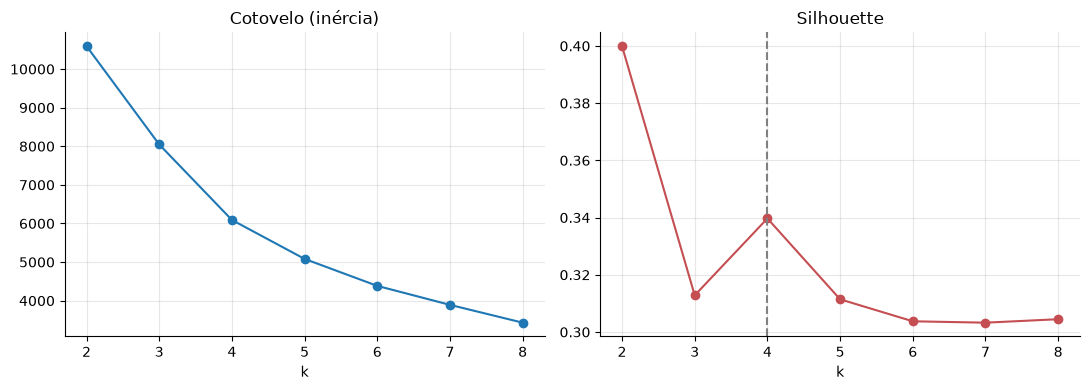

In [18]:
rfm, segmentos, aval_k, k, sil = analise.segmentar_clientes(pedidos)
fig, ax = plt.subplots(1, 2)
aval_k.plot(x="k", y="inercia", marker="o", ax=ax[0], title="Cotovelo (inércia)", legend=False)
aval_k.plot(x="k", y="silhouette", marker="o", ax=ax[1], title="Silhouette", legend=False, color="#C44E52")
ax[1].axvline(k, ls="--", color="gray")
plt.tight_layout()
print(f"k escolhido = {k} | silhouette = {sil:.3f}")
aval_k.round(3)

In [19]:
s = segmentos.copy()
s["pct_clientes"] *= 100; s["pct_receita"] *= 100
s.round(1)

,segmento,clientes,recencia_media,frequencia_media,monetario_medio,receita_total,pct_clientes,pct_receita
0,Campeões,1788,26.80,19.00,"17,618.60","31,501,976.10",26.20,65.80
1,Em risco,1614,310.00,5.30,"5,223.60","8,430,864.10",23.60,17.60
2,Regulares,1941,24.40,4.30,"3,538.40","6,868,059.20",28.40,14.30
3,Hibernando,1491,341.20,1.50,713.70,"1,064,114.40",21.80,2.20


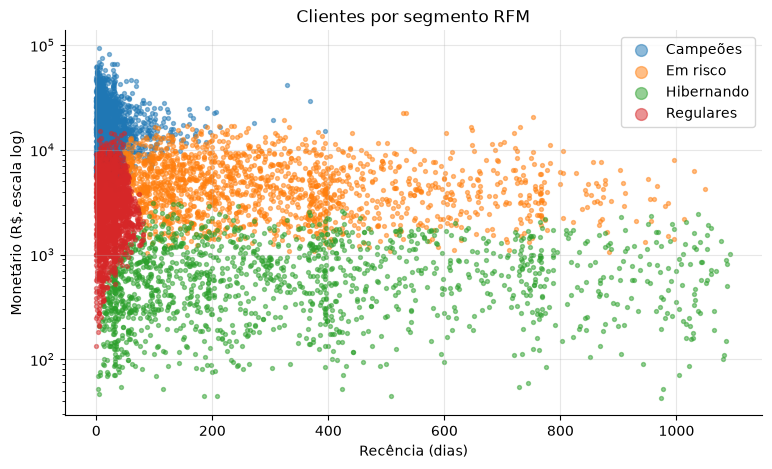

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
for nome, g in rfm.groupby("segmento"):
    ax.scatter(g["recencia_dias"], g["monetario"], s=8, alpha=.5, label=nome)
ax.set_yscale("log"); ax.set_xlabel("Recência (dias)"); ax.set_ylabel("Monetário (R$, escala log)")
ax.legend(markerscale=3); ax.set_title("Clientes por segmento RFM");

## 9. Técnica 2 — Previsão da receita mensal

Candidatos: Holt-Winters (tendência aditiva + sazonalidade multiplicativa), Holt-Winters em log e um **baseline**
sazonal ingênuo (mesmo mês do ano anterior × crescimento dos últimos 12 meses).

**Validação com origem móvel:** treina com os primeiros 24 meses, prevê os 3 seguintes, avança um mês e
repete (10 janelas). O modelo com menor **MAPE médio** é escolhido e reajustado com toda a série.

In [21]:
previsao, metricas, backtest = analise.prever_receita(pedidos)
m = metricas.copy(); m["MAPE"] = (m["MAPE"] * 100).round(2).astype(str) + "%"
m

,modelo,MAPE,MAPE_desvio,MAE,janelas,escolhido
0,"Holt-Winters (tendência aditiva, sazonalidade ...",5.17%,0.02,"83,349.90",10,True
1,Holt-Winters em log (crescimento e sazonalidad...,5.72%,0.02,"105,190.10",10,False
2,Sazonal ingênuo c/ crescimento (baseline),5.79%,0.01,"98,320.82",10,False


,mes,previsto,limite_inferior,limite_superior
42,2026-01-01,"1,670,377.34","1,501,060.69","1,839,693.99"
43,2026-02-01,"1,529,516.38","1,374,478.00","1,684,554.76"
44,2026-03-01,"1,821,740.82","1,637,081.32","2,006,400.33"
45,2026-04-01,"1,689,353.16","1,518,113.03","1,860,593.28"
46,2026-05-01,"2,005,400.96","1,802,124.86","2,208,677.05"
47,2026-06-01,"1,845,749.01","1,658,655.93","2,032,842.09"


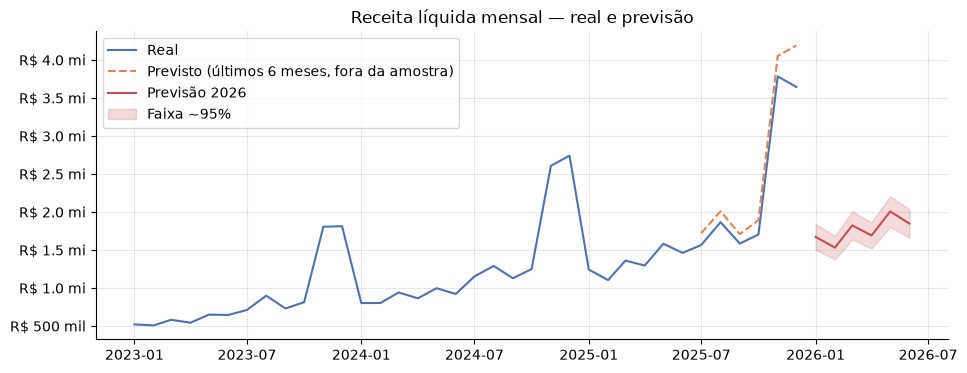

In [22]:
p = previsao.copy(); p["mes"] = pd.to_datetime(p["mes"])
hist = p[p["tipo"] == "histórico"]; tst = p[p["tipo"] == "teste (fora da amostra)"]; fut = p[p["tipo"] == "previsão"]
fig, ax = plt.subplots()
ax.plot(hist["mes"], hist["real"], label="Real", color="#4C72B0")
ax.plot(tst["mes"], tst["previsto"], "--", label="Previsto (últimos 6 meses, fora da amostra)", color="#DD8452")
ax.plot(fut["mes"], fut["previsto"], label="Previsão 2026", color="#C44E52")
ax.fill_between(fut["mes"], fut["limite_inferior"], fut["limite_superior"], alpha=.2, color="#C44E52", label="Faixa ~95%")
ax.yaxis.set_major_formatter(reais); ax.legend(); ax.set_title("Receita líquida mensal — real e previsão")
fut[["mes", "previsto", "limite_inferior", "limite_superior"]]

## 10. Técnica 3 — Detecção de anomalias na receita diária

Cada dia é comparado à mediana móvel de 29 dias; o desvio é convertido em **z-score robusto** (baseado na
mediana dos desvios absolutos, MAD). Dias com |z| > 3,5 são marcados como anômalos.

,data_pedido,receita,referencia,z_robusto,evento
327,2023-11-24,"97,310.00","55,053.00",4.40,Black Friday
328,2023-11-25,"116,761.00","55,053.00",6.40,Black Friday
329,2023-11-26,"118,711.00","55,053.00",6.60,Black Friday
583,2024-08-06,"81,603.00","39,395.00",4.40,Dia dos Pais
671,2024-11-02,"97,713.00","61,267.00",3.80,Nenhum
697,2024-11-28,"114,274.00","79,812.00",3.60,Nenhum
698,2024-11-29,"181,871.00","79,046.00",10.70,Black Friday
699,2024-11-30,"223,421.00","79,046.00",15.00,Black Friday
700,2024-12-01,"195,850.00","78,631.00",12.20,Black Friday
701,2024-12-02,"168,451.00","78,631.00",9.30,Black Friday


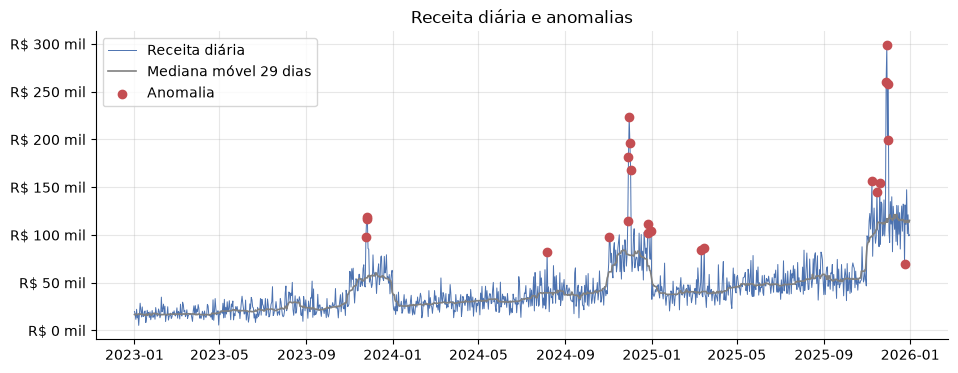

In [23]:
dia = analise.detectar_anomalias(pedidos); dia["data_pedido"] = pd.to_datetime(dia["data_pedido"])
fig, ax = plt.subplots()
ax.plot(dia["data_pedido"], dia["receita"], lw=.7, color="#4C72B0", label="Receita diária")
ax.plot(dia["data_pedido"], dia["referencia"], lw=1.2, color="gray", label="Mediana móvel 29 dias")
an = dia[dia["anomalia"]]
ax.scatter(an["data_pedido"], an["receita"], color="#C44E52", zorder=3, label="Anomalia")
ax.yaxis.set_major_formatter(reais); ax.legend(); ax.set_title("Receita diária e anomalias")
an[["data_pedido", "receita", "referencia", "z_robusto", "evento"]].round({"receita": 0, "referencia": 0, "z_robusto": 1})

In [24]:
an.groupby("evento").size().rename("dias anômalos").to_frame()

,dias anômalos
evento,
Black Friday,11
Dia dos Pais,1
Natal,1
Nenhum,10


## 11. Avaliação crítica e limitações

- **Silhouette ≈ 0,34**: separação moderada. Os segmentos são úteis para ação de negócio, mas há
  sobreposição entre grupos vizinhos (ex.: Regulares × Campeões). Clientes que estão perto da fronteira devem ser
  tratados com cautela.
- **RFM ignora** margem, categoria preferida e canal. Um cliente "Campeão" pode ser pouco lucrativo se só compra
  com desconto.
- **Previsão com 36 meses** = apenas 3 ciclos sazonais. O erro sobe nos meses de Black Friday e Natal, e a faixa
  de ~95% é aproximada (derivada do MAPE do backtest, não de um modelo probabilístico).
- **Anomalias**: a maioria coincide com eventos comerciais conhecidos (esperado). Dias anômalos sem evento
  merecem investigação (campanhas não registradas, falhas de sistema).
- **Dados sintéticos**: os padrões foram simulados a partir de premissas do cenário. Os métodos valem para dados
  reais, mas os números não descrevem uma empresa real. Os preços são constantes ao longo do tempo (sem inflação).
- **Causalidade**: as análises são descritivas e correlacionais; por exemplo, não provam que reduzir o desconto
  manteria o volume da Black Friday. Isso exigiria um teste controlado (A/B).